# Etapa 4: Random Tree

Entrada: as mesmas linhas completas de `data/processed/chembl_4targets.csv` usadas no notebook 03, com os 17 atributos e a divisão agrupada.

A Random Tree é uma árvore de decisão que, em cada nó, sorteia K atributos e escolhe a melhor pergunta só entre eles. No scikit-learn, é o `DecisionTreeClassifier` com `max_features=K`.



## 0. Configuração
Célula 1. Preparação

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

from src import modeling
from src.config import FINAL_CSV, FEATURE_SETS

final = pd.read_csv(FINAL_CSV)
dados = modeling.prepare(final)

## 1. Treino e teste

Mesma divisão agrupada do notebook 03: moléculas com descritores idênticos nunca ficam em lados opostos.
Célula 2. Separar treino e teste


In [2]:
atributos = FEATURE_SETS["descritores + SMILES"]
treino, teste = dados.splits["agrupada"]

X_treino = dados.X[atributos].iloc[treino]
X_teste = dados.X[atributos].iloc[teste]
y_treino = dados.y.iloc[treino]
y_teste = dados.y.iloc[teste]

print(X_treino.shape, X_teste.shape)

(21980, 17) (5496, 17)


## 2. Árvore de decisão × Random Tree

As duas usam os hiperparâmetros escolhidos no notebook 03 (entropia, sem limite de profundidade, sem poda). A única diferença é `max_features`: a árvore testa os 17 atributos em cada nó, e a Random Tree sorteia 5. Célula 3. Uma função que treina e resume a árvore. Célula 4. Treinar as duas e comparar.


In [3]:
def avaliar(modelo):
    modelo.fit(X_treino, y_treino)
    return {
        "acurácia treino": accuracy_score(y_treino, modelo.predict(X_treino)),
        "acurácia teste": accuracy_score(y_teste, modelo.predict(X_teste)),
        "folhas": modelo.get_n_leaves(),
        "profundidade": modelo.get_depth(),
        "atributo da raiz": atributos[modelo.tree_.feature[0]],
        "limiar da raiz": modelo.tree_.threshold[0],
    }

In [4]:
arvore = DecisionTreeClassifier(criterion="entropy", random_state=42)
random_tree = DecisionTreeClassifier(criterion="entropy", max_features=5, random_state=42)

resultados = pd.DataFrame({
    "Árvore de decisão": avaliar(arvore),
    "Random Tree (K=5)": avaliar(random_tree),
})
resultados

,Árvore de decisão,Random Tree (K=5)
acurácia treino,1.0,1.0
acurácia teste,0.896652,0.88246
folhas,1854,2559
profundidade,24,23
atributo da raiz,TPSA,HBD
limiar da raiz,67.895,1.5


**Resultado.** A árvore de decisão reproduz o notebook 03 (0,897; 1.854 folhas; raiz TPSA ≤ 67,9). A Random Tree com K=5 acerta 0,882 no teste, 1,4 ponto a menos, e precisa de 38% mais folhas (2.559), porque, sem o melhor atributo em todos os nós, cada pergunta separa as classes um pouco pior. A profundidade quase não muda (23 contra 24).

A raiz passou a ser HBD ≤ 1,5: a TPSA não foi sorteada (chance de 5 em 17), e a árvore usou um atributo correlacionado, que também mede polaridade. Este é um resultado de uma semente só; a variação entre sementes é medida no experimento 3.

## 3. Qual é o melhor K?

Acurácia de treino e de validação cruzada (5 partes agrupadas, dentro do treino) para K = 1, 2, 3, 5, 8, 12 e 17. K = 17 é a árvore de decisão. O conjunto de teste não é usado nesta escolha.

Célula de código: a curva.

In [5]:
from sklearn.model_selection import StratifiedGroupKFold, validation_curve
from src.config import CV_FOLDS

valores_k = [1, 2, 3, 5, 8, 12, 17]
grupos_treino = dados.grupos[treino]
cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)

acc_treino, acc_validacao = validation_curve(
    DecisionTreeClassifier(criterion="entropy", random_state=42),
    X_treino, y_treino,
    param_name="max_features", param_range=valores_k,
    groups=grupos_treino, cv=cv, n_jobs=-1,
)

curva_k = pd.DataFrame({
    "K": valores_k,
    "treino": acc_treino.mean(axis=1),
    "validação": acc_validacao.mean(axis=1),
    "desvio validação": acc_validacao.std(axis=1),
})
curva_k

,K,treino,validação,desvio validação
0,1,1.0,0.797771,0.006596
1,2,1.0,0.836715,0.008119
2,3,1.0,0.858053,0.008014
3,5,1.0,0.870928,0.010323
4,8,1.0,0.874340,0.007257
5,12,1.0,0.872384,0.010540
6,17,1.0,0.878344,0.005134


Célula de código: o gráfico

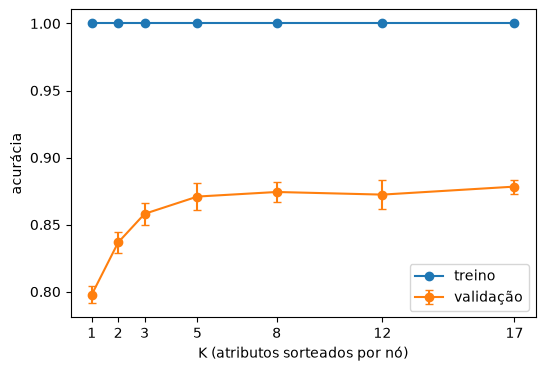

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(curva_k["K"], curva_k["treino"], marker="o", label="treino")
ax.errorbar(curva_k["K"], curva_k["validação"], yerr=curva_k["desvio validação"],
            marker="o", capsize=3, label="validação")
ax.set_xlabel("K (atributos sorteados por nó)")
ax.set_ylabel("acurácia")
ax.set_xticks(valores_k)
ax.legend()
plt.show()

**Resultado.** A acurácia de treino é 100% para todo K: sem limite de profundidade, a árvore divide até as folhas ficarem puras. A validação sobe rápido de K=1 (0,798) a K=5 (0,871) e forma um platô: de K=5 a K=17 (0,878, igual ao notebook 03) as diferenças são menores que 1 ponto, do tamanho do desvio entre as partes da validação cruzada.

Para uma árvore sozinha, sortear atributos não melhora a acurácia; no máximo empata. A partir de K=5 a aleatoriedade custa menos de 1 ponto. Os próximos experimentos usam K=5.


## 4. Instabilidade: a mesma Random Tree com 30 sementes

A Random Tree (K=5) e a árvore de decisão são treinadas 30 vezes nos mesmos dados, mudando apenas `random_state`. Medem-se a variação da acurácia de teste, o atributo da raiz e se as árvores erram nas mesmas moléculas.

Célula de código: treinar as 60 árvores

In [7]:
linhas = []
previsoes = {}

for semente in range(30):
    for nome, k in [("Árvore de decisão", None), ("Random Tree (K=5)", 5)]:
        modelo = DecisionTreeClassifier(criterion="entropy", max_features=k, random_state=semente)
        resultado = avaliar(modelo)
        resultado["modelo"] = nome
        resultado["semente"] = semente
        linhas.append(resultado)
        if k == 5:
            previsoes[semente] = modelo.predict(X_teste)

sementes_df = pd.DataFrame(linhas)
sementes_df.head()

,acurácia treino,acurácia teste,folhas,profundidade,atributo da raiz,limiar da raiz,modelo,semente
0,1.0,0.898108,1854,24,TPSA,67.895,Árvore de decisão,0
1,1.0,0.860626,2719,22,TPSA,67.895,Random Tree (K=5),0
2,1.0,0.896288,1853,24,TPSA,67.895,Árvore de decisão,1
3,1.0,0.866812,2653,23,n_aromatic,13.500,Random Tree (K=5),1
4,1.0,0.895560,1852,24,TPSA,67.895,Árvore de decisão,2


Célula de código: resumo da acurácia e das raízes

In [8]:
resumo = sementes_df.groupby("modelo")[["acurácia teste", "folhas"]].agg(["mean", "std", "min", "max"])
display(resumo)
display(sementes_df.groupby("modelo")["atributo da raiz"].value_counts())

acurácia teste                                     folhas  \
                            mean       std       min       max         mean   
modelo                                                                        
Random Tree (K=5)       0.875619  0.008428  0.857897  0.888464  2582.100000   
Árvore de decisão       0.895008  0.002037  0.891921  0.898472  1852.933333   

                                          
                         std   min   max  
modelo                                    
Random Tree (K=5)  91.865475  2447  2805  
Árvore de decisão   2.116167  1848  1858

modelo             atributo da raiz
Random Tree (K=5)  TPSA                 9
                   n_double             6
                   n_aromatic           4
                   HBD                  3
                   n_branch             3
                   n_N                  1
                   smiles_len           1
                   n_stereo             1
                   n_halogen            1
                   HBA                  1
Árvore de decisão  TPSA                30
Name: count, dtype: int64

Célula de código: as árvores erram nas mesmas moléculas?

In [9]:
acertos = pd.DataFrame({s: p == y_teste.to_numpy() for s, p in previsoes.items()})
n_acertos = acertos.sum(axis=1)

distribuicao = n_acertos.value_counts().sort_index()
distribuicao

0       11
1       13
2        5
3       15
4       15
5       24
6       20
7       25
8       13
9       21
10      24
11      36
12      38
13      33
14      48
15      43
16      56
17      63
18      63
19      65
20      87
21     118
22     111
23     138
24     161
25     202
26     248
27     341
28     512
29     787
30    2160
Name: count, dtype: int64

Célula de código: o gráfico da distribuição

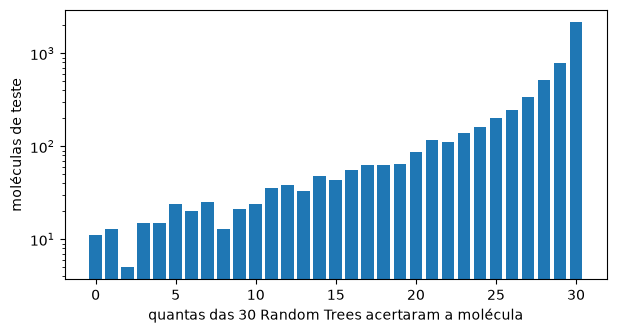

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(distribuicao.index, distribuicao.values)
ax.set_xlabel("quantas das 30 Random Trees acertaram a molécula")
ax.set_ylabel("moléculas de teste")
ax.set_yscale("log")
plt.show()

**Resultado.** Nas 30 sementes, a árvore de decisão fica entre 0,892 e 0,898 (desvio de 0,2 ponto) e sempre tem TPSA ≤ 67,9 na raiz: a semente só desempata perguntas igualmente boas nos nós mais fundos. A Random Tree (K=5) varia quatro vezes mais, de 0,858 a 0,888 (desvio de 0,8 ponto), com média de 0,876. A TPSA é a raiz em 9 das 30 (30%, contra 29% esperados) e aparecem 10 raízes diferentes.

As Random Trees erram em moléculas diferentes: só 11 das 5.496 moléculas de teste são erradas pelas 30 árvores, 2.160 são acertadas por todas e cerca de 60% ficam no meio. Como só 384 moléculas têm 15 acertos ou menos, a votação das 30 árvores acertaria pelo menos 93,0%.

## 5. Votação: de uma Random Tree à Random Forest

Conjuntos de 1 a 300 Random Trees (K=5, entropia) votando juntas, com e sem bootstrap. Sem bootstrap, as árvores só diferem pelo sorteio de atributos; com bootstrap, cada uma treina numa amostra com reposição diferente, que é a Random Forest completa.

Célula de código: treinar os conjuntos

In [11]:
import time
from sklearn.ensemble import RandomForestClassifier

quantidades = [1, 5, 10, 30, 100, 300]
linhas_votacao = []

for bootstrap in [False, True]:
    for n in quantidades:
        floresta = RandomForestClassifier(
            n_estimators=n, criterion="entropy", max_features=5,
            bootstrap=bootstrap, random_state=42, n_jobs=-1,
        )
        inicio = time.perf_counter()
        floresta.fit(X_treino, y_treino)
        tempo = time.perf_counter() - inicio
        linhas_votacao.append({
            "bootstrap": "com bootstrap" if bootstrap else "sem bootstrap",
            "árvores": n,
            "acurácia teste": accuracy_score(y_teste, floresta.predict(X_teste)),
            "tempo de treino (s)": round(tempo, 2),
        })

votacao = pd.DataFrame(linhas_votacao)
votacao.pivot(index="árvores", columns="bootstrap", values="acurácia teste")

bootstrap,com bootstrap,sem bootstrap
árvores,,
1,0.855531,0.882278
5,0.921761,0.935226
10,0.936499,0.942322
30,0.946143,0.951783
100,0.951419,0.954694
300,0.952875,0.955968


Célula de código: o gráfico

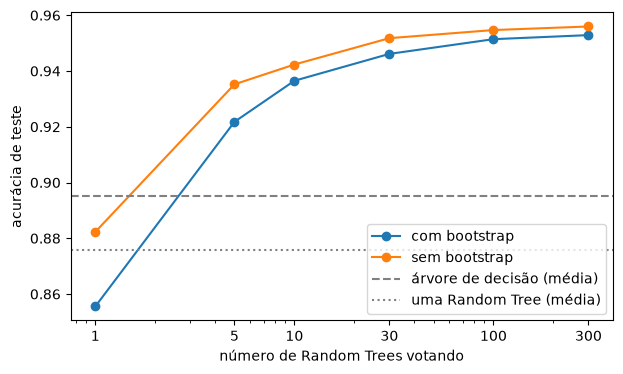

In [12]:
medias = sementes_df.groupby("modelo")["acurácia teste"].mean()

fig, ax = plt.subplots(figsize=(7, 4))
for nome, grupo in votacao.groupby("bootstrap"):
    ax.plot(grupo["árvores"], grupo["acurácia teste"], marker="o", label=nome)
ax.axhline(medias["Árvore de decisão"], color="gray", linestyle="--", label="árvore de decisão (média)")
ax.axhline(medias["Random Tree (K=5)"], color="gray", linestyle=":", label="uma Random Tree (média)")
ax.set_xscale("log")
ax.set_xticks(quantidades)
ax.set_xticklabels(quantidades)
ax.set_xlabel("número de Random Trees votando")
ax.set_ylabel("acurácia de teste")
ax.legend()
plt.show()

**Resultado.** Cinco Random Trees votando já chegam a 0,935 sem bootstrap, acima da árvore de decisão (0,895). Com 300 árvores, a votação chega a 0,956 sem bootstrap e 0,953 com bootstrap; esta última reproduz a Random Forest do notebook 03 (0,952). O ganho achata a partir de 100 árvores: de 100 para 300 a acurácia sobe no máximo 0,3 ponto.

O bootstrap não ajuda nesta base. Cada amostra com reposição deixa de fora cerca de 37% das moléculas, e cada árvore fica mais fraca (0,856 contra 0,882 com uma árvore só); a diversidade que o bootstrap traria já vem do sorteio de atributos. Com poucas árvores, a versão sem bootstrap vence por 0,6 a 2,7 pontos; com 100 ou mais, as duas empatam dentro da variação observada entre seeds (0,3 ponto). O ganho da Random Forest vem, sobretudo, do sorteio de atributos com votação.